In [39]:
# import

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [40]:
# pull data from csv file
data = pd.read_csv('bank.csv')
data_full = pd.read_csv('bank-full.csv')

In [41]:
# check the first 5 rows of the data
data.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


In [42]:
# check the first 5 rows of the full data
data_full.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


# ข้อมูลลูกค้าธนาคาร (Bank Client Data)
1. age – อายุของลูกค้า (ข้อมูลตัวเลข)
2. job – ประเภทอาชีพของลูกค้า (ข้อมูลหมวดหมู่)
   - admin. = พนักงานธุรการ
   - unknown = ไม่ทราบอาชีพ
   - unemployed = ว่างงาน
   - management = ผู้บริหาร / ผู้จัดการ
   - housemaid = แม่บ้าน
   - entrepreneur = ผู้ประกอบการ / เจ้าของธุรกิจ
   - student = นักเรียน / นักศึกษา
   - blue-collar = ผู้ใช้แรงงาน
   - self-employed = ประกอบอาชีพอิสระ
   - retired = เกษียณอายุ
   - technician = ช่างเทคนิค
   - services = พนักงานบริการ
3. marital – สถานภาพสมรส
   - married = สมรส
   - divorced = หย่าร้าง หรือคู่สมรสเสียชีวิต
   - single = โสด
4. education – ระดับการศึกษา
   - unknown = ไม่ทราบ
   - secondary = มัธยมศึกษา
   - primary = ประถมศึกษา
   - tertiary = อุดมศึกษา / ระดับมหาวิทยาลัย
5. default – มีประวัติผิดนัดชำระหนี้หรือไม่
   - yes = มี
   - no = ไม่มี
6. balance – ยอดเงินคงเหลือเฉลี่ยรายปี (หน่วยยูโร)
7. housing – มีสินเชื่อที่อยู่อาศัยหรือไม่
   - yes = มี
   - no = ไม่มี
8. loan – มีสินเชื่อส่วนบุคคลหรือไม่
   - yes = มี
   - no = ไม่มี
# ข้อมูลการติดต่อลูกค้าครั้งล่าสุด (Last Contact Information)
9. contact – ประเภทช่องทางการติดต่อลูกค้า
   - unknown = ไม่ทราบช่องทาง
   - telephone = โทรศัพท์พื้นฐาน
   - cellular = โทรศัพท์มือถือ
10. day – วันที่ติดต่อลูกค้าครั้งล่าสุด (วันที่ของเดือน)
11. month – เดือนที่ติดต่อลูกค้าครั้งล่าสุด
- jan = มกราคม
- feb = กุมภาพันธ์
- mar = มีนาคม
- apr = เมษายน
- may = พฤษภาคม
- jun = มิถุนายน
- jul = กรกฎาคม
- aug = สิงหาคม
- sep = กันยายน
- oct = ตุลาคม
- nov = พฤศจิกายน
- dec = ธันวาคม
12. duration – ระยะเวลาที่ติดต่อลูกค้าครั้งล่าสุด (หน่วยวินาที)
# ข้อมูลอื่น ๆ เกี่ยวกับแคมเปญการตลาด (Other Attributes)
13. campaign – จำนวนครั้งที่ติดต่อลูกค้าในแคมเปญปัจจุบัน (รวมการติดต่อล่าสุด)
14. pdays – จำนวนวันที่ผ่านไปนับจากการติดต่อลูกค้าครั้งล่าสุดในแคมเปญก่อนหน้า
- -1 = ไม่เคยติดต่อลูกค้ามาก่อน
15. previous – จำนวนครั้งที่เคยติดต่อลูกค้าก่อนแคมเปญปัจจุบัน
16. poutcome – ผลลัพธ์ของแคมเปญการตลาดครั้งก่อน
- unknown = ไม่ทราบผลลัพธ์
- other = ผลลัพธ์อื่น ๆ
- failure = ไม่ประสบความสำเร็จ
- success = ประสบความสำเร็จ
# ตัวแปรเป้าหมาย (Output Variable / Target)
17. y – ลูกค้าสมัครใช้บริการเงินฝากประจำ (Term Deposit) หรือไม่
- yes = สมัครเงินฝากประจำ
- no = ไม่สมัครเงินฝากประจำ

In [43]:
# check type of data
print(data_full.dtypes)

age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object


# ส่วนที่ 1: Exploratory Data Analysis

# Distribution of Duration
จงวิเคราะห์การกระจายของตัวแปร duration โดยใช้ Histogram และ Boxplot พร้อมอธิบายลักษณะการกระจายของข้อมูลว่ามีความเบ้ (Skewness) หรือค่าผิดปกติ (Outliers) หรือไม่

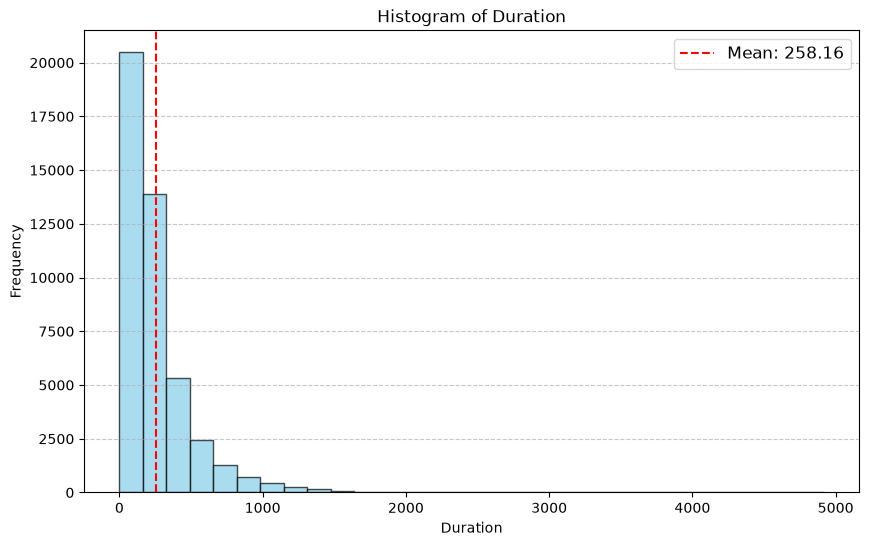

In [44]:
# create Histogram of duration
plt.figure(figsize=(10, 6))
plt.hist(data_full['duration'], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Histogram of Duration')
plt.xlabel('Duration')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add annotations
mean_value = data_full['duration'].mean()
plt.axvline(mean_value, color='red', linestyle='dashed', linewidth=1.5, label=f'Mean: {mean_value:.2f}')
plt.legend(fontsize=12)
plt.show()

C:\Users\Maru\AppData\Local\Temp\ipykernel_5056\2105101794.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(data_full['duration'], vert=True, patch_artist=True,


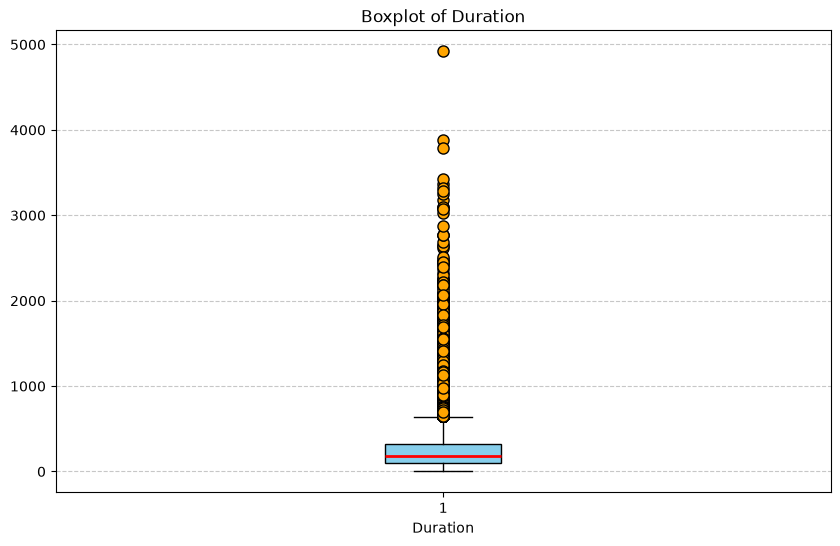

In [45]:
# create Boxplot of duration
plt.figure(figsize=(10, 6))
plt.boxplot(data_full['duration'], vert=True, patch_artist=True,
            boxprops=dict(facecolor="skyblue", color="black"),
            medianprops=dict(color="red", linewidth=2),
            whiskerprops=dict(color="black", linewidth=1),
            capprops=dict(color="black", linewidth=1),
            flierprops=dict(markerfacecolor="orange", marker="o", markersize=8))
plt.title('Boxplot of Duration')
plt.xlabel('Duration')
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

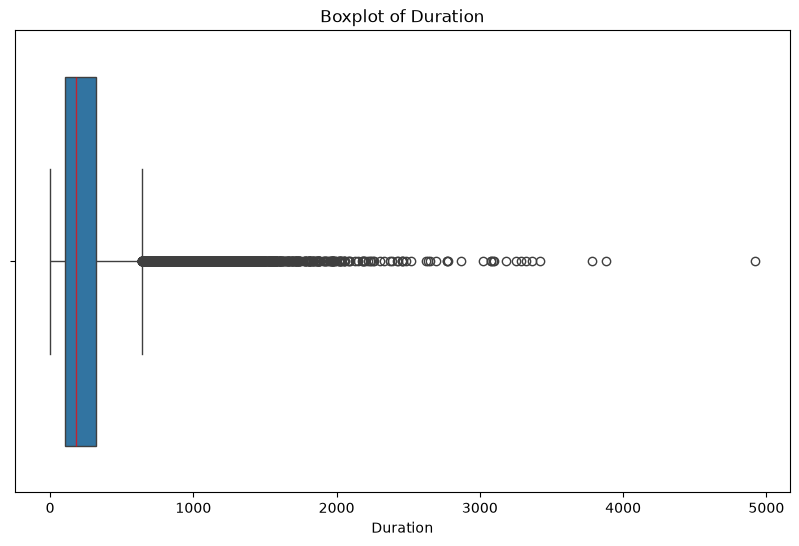

In [46]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=data_full, x='duration', medianprops=dict(color="red", alpha=0.7))
plt.title('Boxplot of Duration')
plt.xlabel('Duration')
plt.show()

2. (4 คะแนน) Duration vs Target
จงเปรียบเทียบการกระจายของตัวแปร duration ระหว่างกลุ่มลูกค้าที่สมัคร (y = yes) และไม่สมัคร (y = no) โดยใช้ Boxplot หรือ Violin Plot พร้อมสรุปข้อค้นพบ (Insights) จากการเปรียบเทียบ

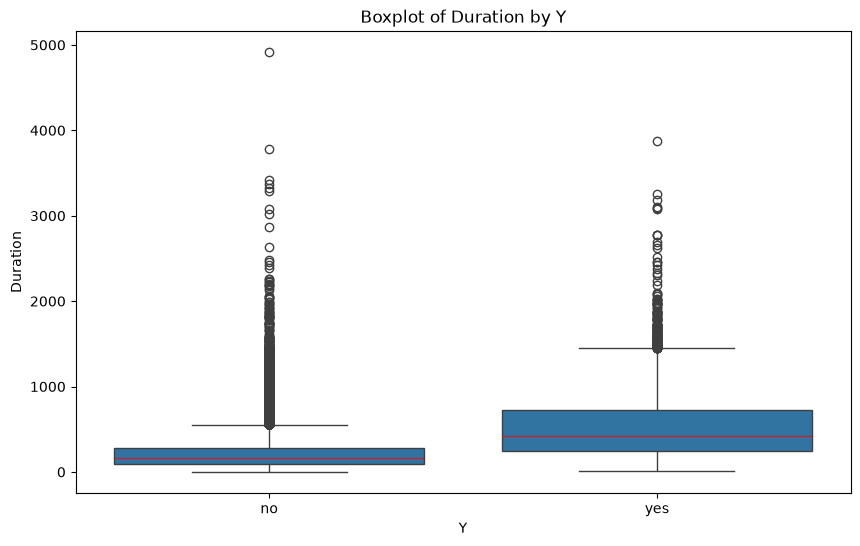

In [47]:
# create Boxplot of duration by y
plt.figure(figsize=(10, 6))
sns.boxplot(data=data_full, x='y', y='duration', medianprops=dict(color="red", alpha=0.7))
plt.title('Boxplot of Duration by Y')
plt.xlabel('Y')
plt.ylabel('Duration')
plt.show()

3. (4 คะแนน) Categorical Variables Exploration
จงวิเคราะห์ตัวแปรเชิงหมวดหมู่ (Categorical Variables) ได้แก่ job, marital และ education โดยใช้ Countplot และ Barplot พร้อมอธิบายว่ากลุ่มลูกค้าใดมีอัตราการสมัคร Term Deposit สูงกว่าค่าเฉลี่ยโดยรวม

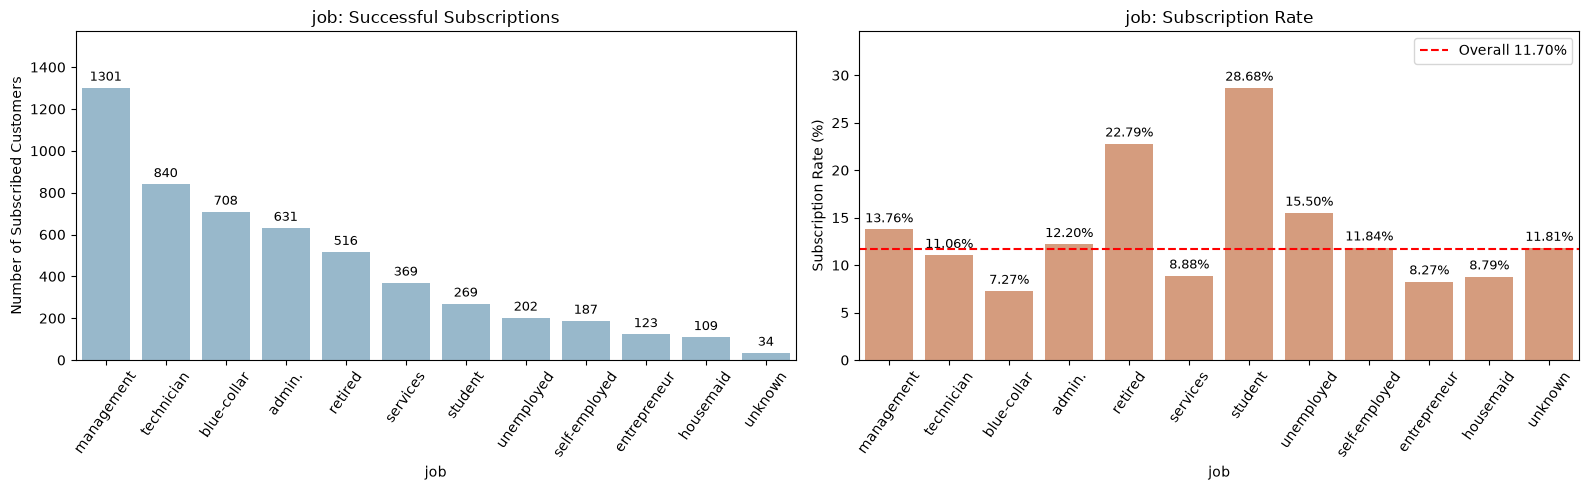

job: Above overall subscription rate (11.70%)


,rate_pct,total
job,,
student,28.68,938
retired,22.79,2264
unemployed,15.50,1303
management,13.76,9458
admin.,12.20,5171
self-employed,11.84,1579
unknown,11.81,288


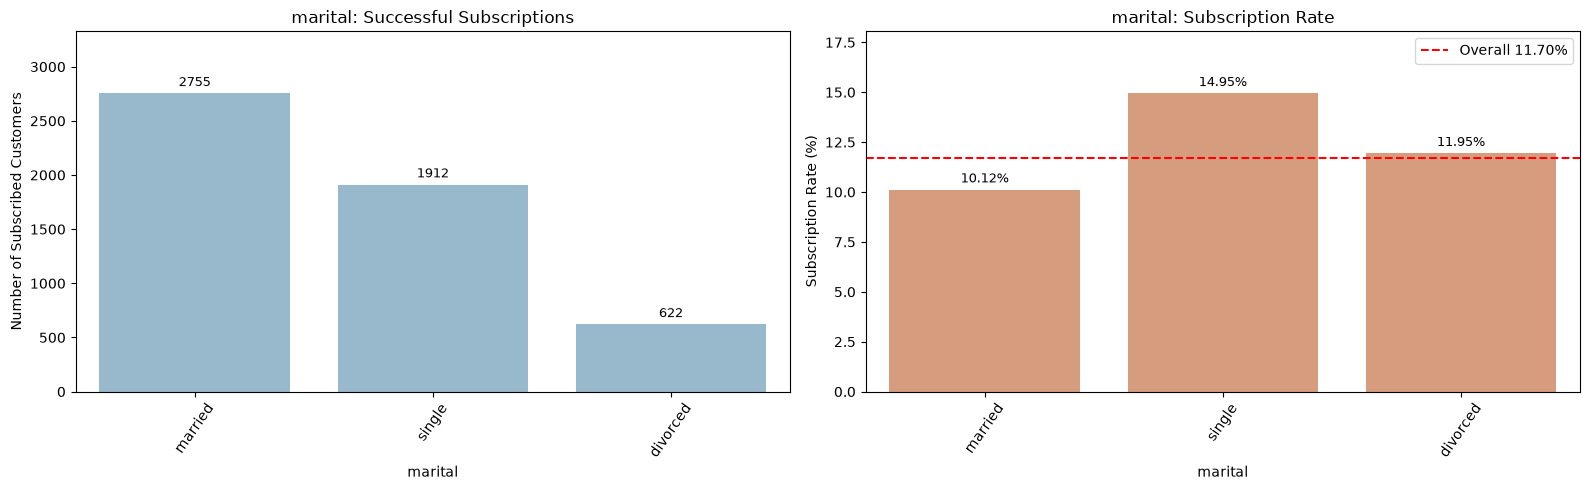

marital: Above overall subscription rate (11.70%)


,rate_pct,total
marital,,
single,14.95,12790
divorced,11.95,5207


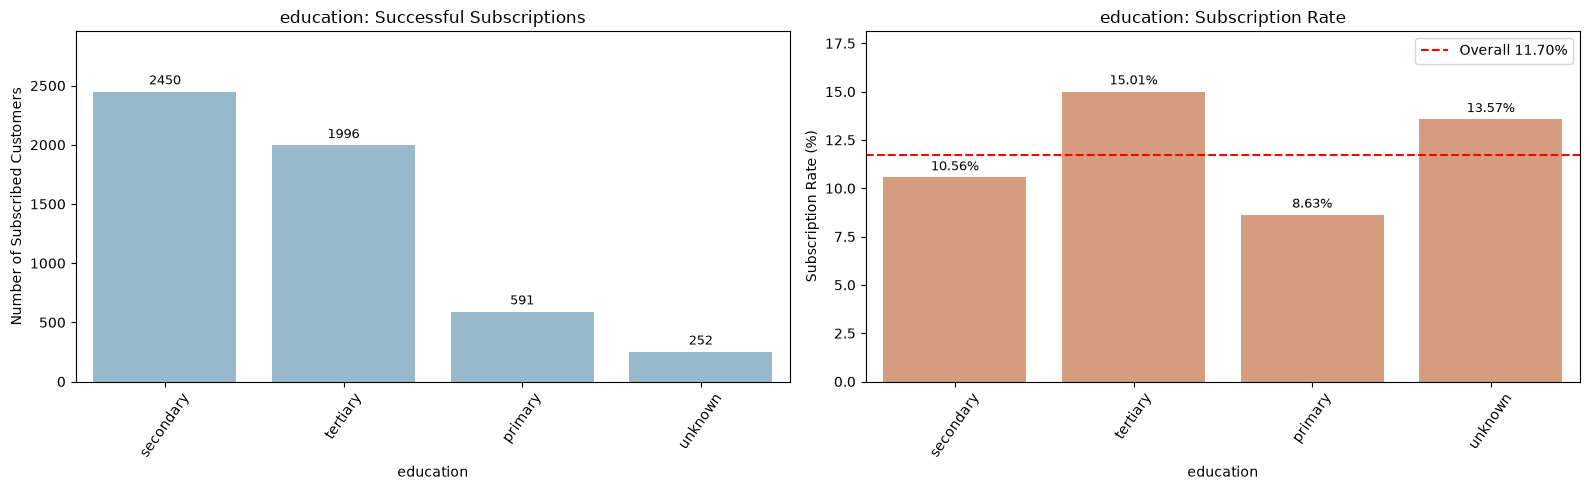

education: Above overall subscription rate (11.70%)


,rate_pct,total
education,,
tertiary,15.01,13301
unknown,13.57,1857


In [48]:

# create countplot of job, marital and education
data_full['subscribed'] = (data_full['y'] == 'yes').astype(int)

# ฟังก์ชันคำนวณอัตราการสมัครตามกลุ่ม
def rates_by(col):
    result = data_full.groupby(col)['subscribed'].agg(
        total='count',
        subscribed='sum',
        rate='mean'
    )

    result['rate_pct'] = result['rate'] * 100
    return result

# คำนวณอัตราการสมัครเฉลี่ยของลูกค้าทั้งหมด
overall = 100 * data_full['subscribed'].mean()

# คัดเฉพาะลูกค้าที่สมัคร Term Deposit สำเร็จ
df_yes = data_full[data_full['subscribed'] == 1].copy()

for col in ['job', 'marital', 'education']:

    # เรียงกลุ่มตามจำนวนลูกค้าที่สมัครสำเร็จ
    order = df_yes[col].value_counts().index

    fig, ax = plt.subplots(1, 2, figsize=(16, 5))

    # กราฟที่ 1: จำนวนลูกค้าที่สมัครสำเร็จ
    sns.countplot(
        data=df_yes,
        x=col,
        order=order,
        ax=ax[0],
        color='#8fbad4'
    )

    ax[0].set_title(f'{col}: Successful Subscriptions')
    ax[0].set_xlabel(col)
    ax[0].set_ylabel('Number of Subscribed Customers')

    # เพิ่มตัวเลขจำนวนลูกค้าบนแท่งกราฟ
    for container in ax[0].containers:
        ax[0].bar_label(
            container,
            fmt='%.0f',
            padding=3,
            fontsize=9
        )

    # กราฟที่ 2: อัตราการสมัครของแต่ละกลุ่ม
    r = rates_by(col).reindex(order)

    sns.barplot(
        x=r.index,
        y=r['rate_pct'].values,
        ax=ax[1],
        color='#e39770',
        errorbar=None
    )

    # เพิ่มตัวเลขเปอร์เซ็นต์บนแท่งกราฟ
    for container in ax[1].containers:
        ax[1].bar_label(
            container,
            fmt='%.2f%%',
            padding=3,
            fontsize=9
        )

    # เส้นแสดงอัตราการสมัครเฉลี่ยโดยรวม
    ax[1].axhline(
        overall,
        color='red',
        linestyle='--',
        label=f'Overall {overall:.2f}%'
    )

    ax[1].set_title(f'{col}: Subscription Rate')
    ax[1].set_xlabel(col)
    ax[1].set_ylabel('Subscription Rate (%)')
    ax[1].legend()

    # เพิ่มพื้นที่ด้านบนเพื่อไม่ให้ตัวเลขถูกตัด
    for a in ax:
        a.set_ylim(0, a.get_ylim()[1] * 1.15)
        a.tick_params(axis='x', rotation=55)

    plt.tight_layout()
    plt.show()

    # แสดงกลุ่มที่มีอัตราการสมัครสูงกว่าค่าเฉลี่ยรวม
    print(f'{col}: Above overall subscription rate ({overall:.2f}%)')

    display(
        rates_by(col)
        .query('rate_pct > @overall')[['rate_pct', 'total']]
        .sort_values('rate_pct', ascending=False)
        .round(2)
    )


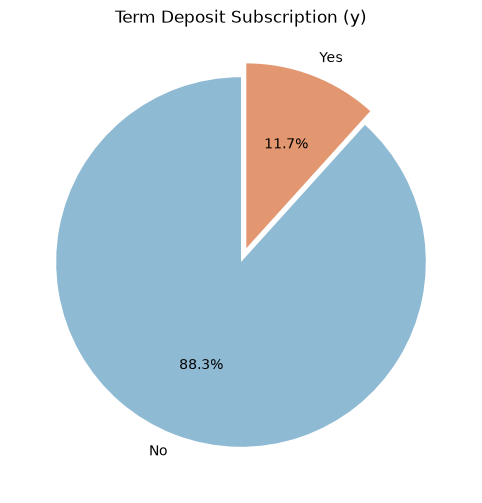

In [49]:
import matplotlib.pyplot as plt

# นับจำนวนลูกค้าแต่ละกลุ่ม
counts = data_full['y'].value_counts()

# สร้าง pie chart
plt.figure(figsize=(6, 6))
plt.pie(
    counts,
    labels=['No', 'Yes'],   # ถ้า value_counts ออก no ก่อน yes
    autopct='%1.1f%%',
    startangle=90,
    colors=['#8fbad4', '#e39770'],
    explode=(0, 0.08)
)

plt.title('Term Deposit Subscription (y)')
plt.show()

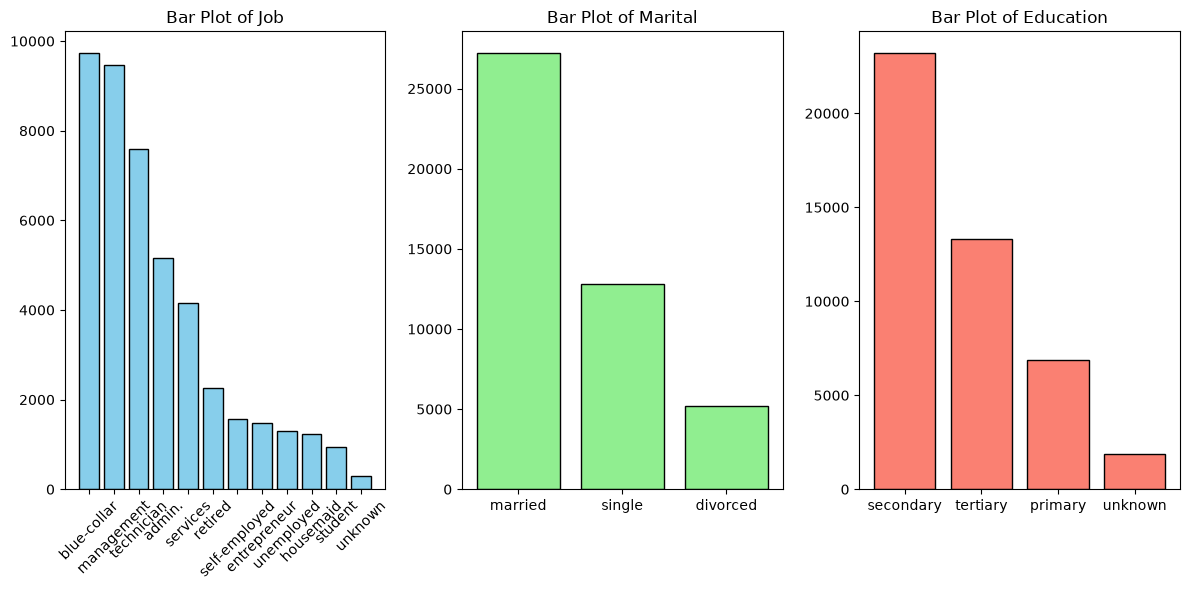

In [50]:
# create bar plot of job, marital and education
plt.figure(figsize=(12, 6))
plt.subplot(1, 3, 1)
job_counts = data_full['job'].value_counts()
plt.bar(job_counts.index, job_counts.values, color='skyblue', edgecolor='black')
plt.title('Bar Plot of Job')
plt.xticks(rotation=45)
plt.subplot(1, 3, 2)
marital_counts = data_full['marital'].value_counts()
plt.bar(marital_counts.index, marital_counts.values, color='lightgreen', edgecolor='black')
plt.title('Bar Plot of Marital')
plt.subplot(1, 3, 3)
education_counts = data_full['education'].value_counts()
plt.bar(education_counts.index, education_counts.values, color='salmon', edgecolor='black')
plt.title('Bar Plot of Education')
plt.tight_layout()
plt.show()

4. (4 คะแนน) Correlation Matrix
จงสร้างเมทริกซ์สหสัมพันธ์ (Correlation Matrix) สำหรับตัวแปรเชิงตัวเลข (Numeric Variables) ได้แก่ age, balance, campaign, pdays, previous และ duration โดยแสดงผลด้วย Heatmap พร้อมวิเคราะห์และตีความความสัมพันธ์ที่สำคัญระหว่างตัวแปร

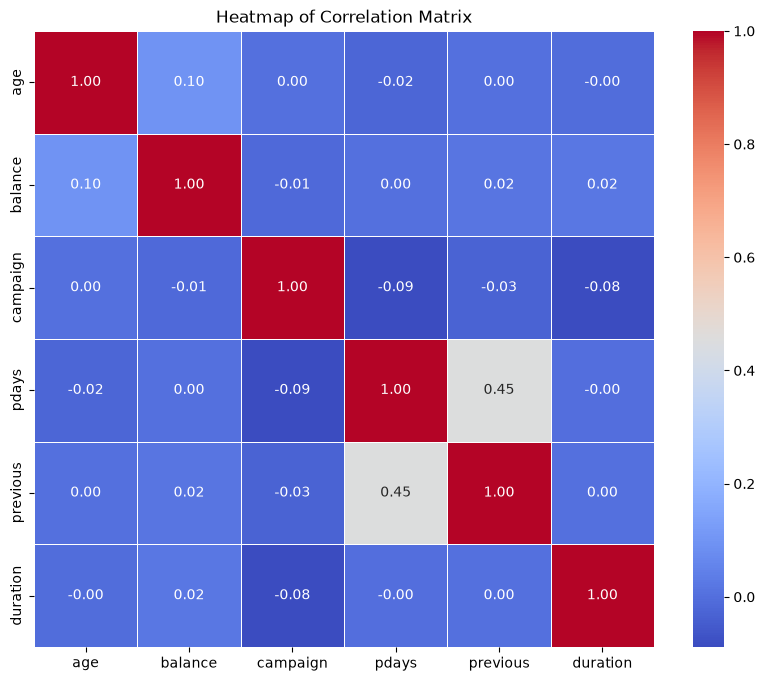

In [51]:
# create heatmap of age, balance, campaign, pdays, previous and duration
plt.figure(figsize=(10, 8))
correlation_matrix = data_full[['age', 'balance', 'campaign', 'pdays', 'previous', 'duration']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Heatmap of Correlation Matrix')
plt.show()

5. (4 คะแนน) Temporal Pattern Analysis
จงวิเคราะห์รูปแบบการสมัคร Term Deposit (y) ตามตัวแปร month และ day โดยใช้ Lineplot หรือ Barplot พร้อมอธิบายว่ามีรูปแบบตามฤดูกาล (Seasonality) หรือช่วงเวลาที่ลูกค้ามีอัตราการสมัครสูงเป็นพิเศษหรือไม่

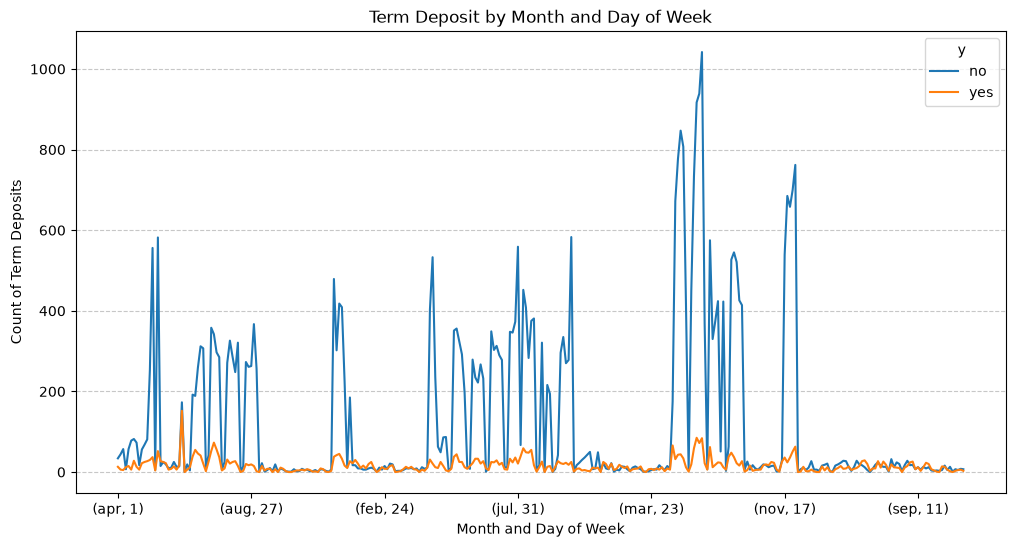

In [52]:
# create line plot of Term Depositby by month and day
plt.figure(figsize=(12, 6))
# Group by month and day, then count the number of term deposits
term_deposit_counts = data_full.groupby(['month', 'day'])['y'].value_counts().unstack().fillna(0)
term_deposit_counts.plot(kind='line', ax=plt.gca())
plt.title('Term Deposit by Month and Day of Week')
plt.xlabel('Month and Day of Week')
plt.ylabel('Count of Term Deposits')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

6. (4 คะแนน) Balance Distribution
จงวิเคราะห์การกระจายของตัวแปร balance โดยใช้ Histogram และ Boxplot พร้อมเปรียบเทียบว่าลูกค้าที่มียอดเงินคงเหลือสูงหรือต่ำมีแนวโน้มสมัคร Term Deposit แตกต่างกันหรือไม่

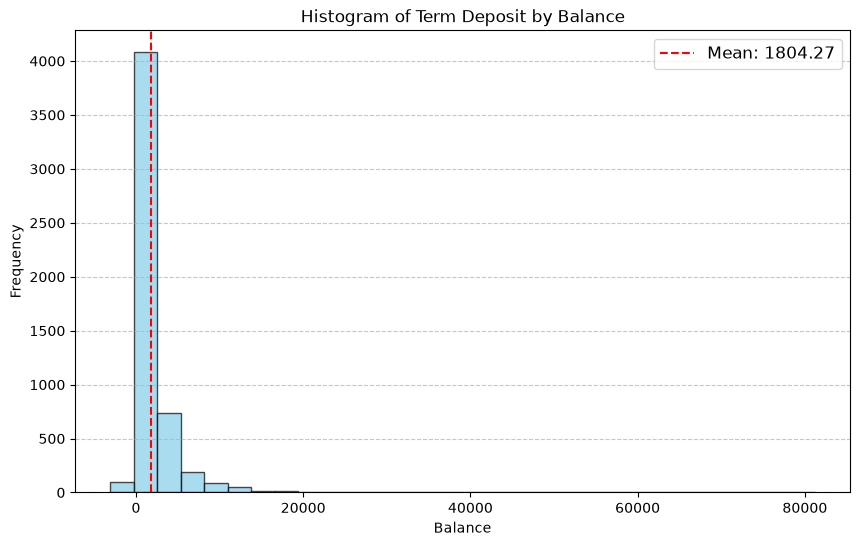

In [53]:
# create Histogram of Term Deposit by balance
plt.figure(figsize=(10, 6))
# Filter the data for term deposits (y == 'yes')
term_deposit_data = data_full[data_full['y'] == 'yes']
plt.hist(term_deposit_data['balance'], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Histogram of Term Deposit by Balance')
plt.xlabel('Balance')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
# Add annotations
mean_balance = term_deposit_data['balance'].mean()
plt.axvline(mean_balance, color='red', linestyle='dashed', linewidth=1.5, label=f'Mean: {mean_balance:.2f}')
plt.legend(fontsize=12)
plt.show()

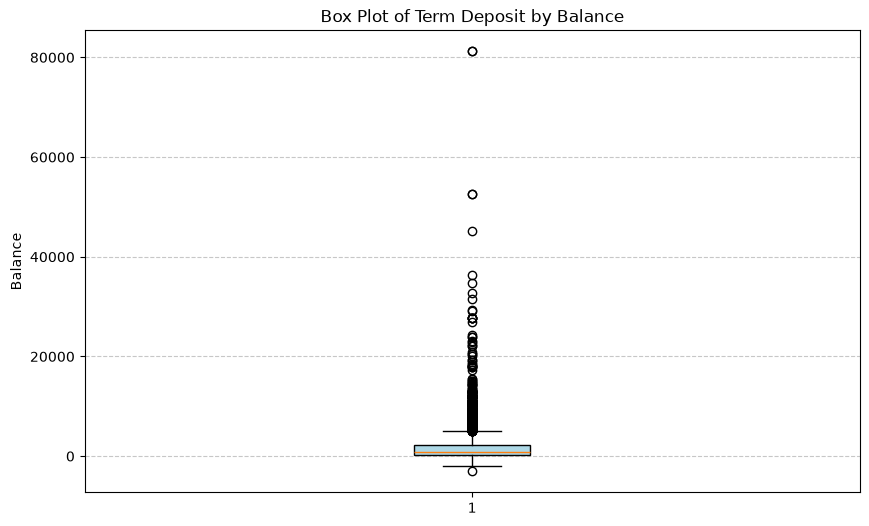

In [54]:
# create Box Plot of Term Deposit by balance
plt.figure(figsize=(10, 6))
# Filter the data for term deposits (y == 'yes')
term_deposit_data = data_full[data_full['y'] == 'yes']
plt.boxplot(term_deposit_data['balance'], patch_artist=True, boxprops=dict(facecolor='lightblue'))
plt.title('Box Plot of Term Deposit by Balance')
plt.ylabel('Balance')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

7. (4 คะแนน) Loan & Housing Loan Analysis
จงวิเคราะห์ความสัมพันธ์ระหว่างการมีสินเชื่อที่อยู่อาศัย (Housing Loan) และสินเชื่อส่วนบุคคล (Personal Loan) กับการสมัคร Term Deposit โดยใช้ Stacked Barplot หรือ Crosstab Heatmap พร้อมสรุปข้อค้นพบ (Insights) จากการวิเคราะห์

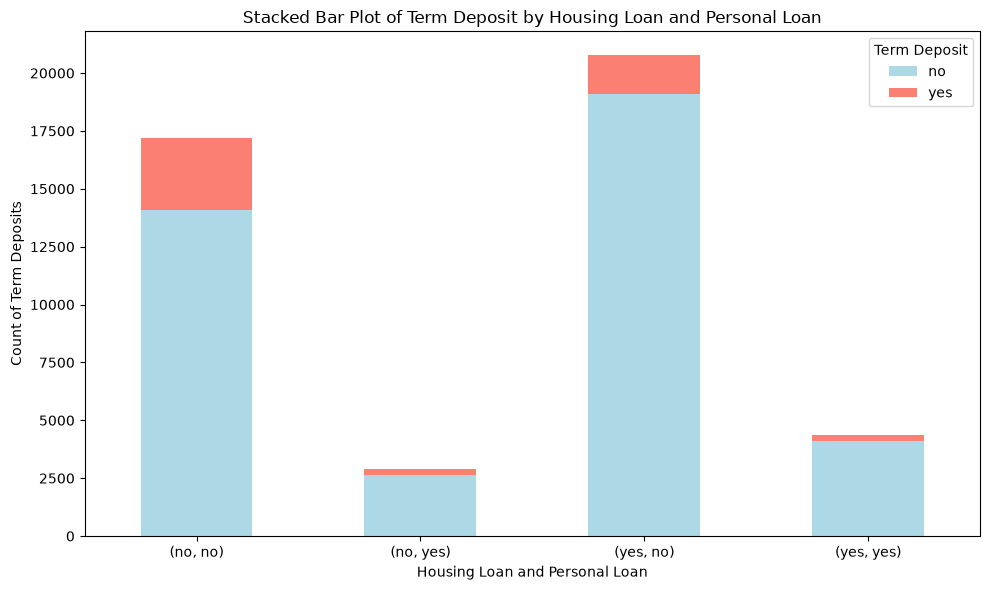

In [55]:
# create Stacked Bar Plot of Term Deposit by Housing Loan and Personal Loan
plt.figure(figsize=(10, 6))
# Create a crosstab of housing and personal loans against term deposit
loan_crosstab = pd.crosstab(index=[data_full['housing'], data_full['loan']], columns=data_full['y'])
loan_crosstab.plot(kind='bar', stacked=True, color=['lightblue', 'salmon'], ax=plt.gca())
plt.title('Stacked Bar Plot of Term Deposit by Housing Loan and Personal Loan')
plt.xlabel('Housing Loan and Personal Loan')
plt.ylabel('Count of Term Deposits')
plt.xticks(rotation=0)
plt.legend(title='Term Deposit', loc='upper right')
plt.tight_layout()
plt.show()

8. (4 คะแนน) Job Category Impact
จงวิเคราะห์ว่าอาชีพใด (job) มีอัตราการสมัคร Term Deposit สูงที่สุด โดยใช้ Barplot แสดงสัดส่วนของลูกค้าที่สมัคร (y = yes) และไม่สมัคร (y = no) ในแต่ละกลุ่มอาชีพ พร้อมอธิบายผลการวิเคราะห์

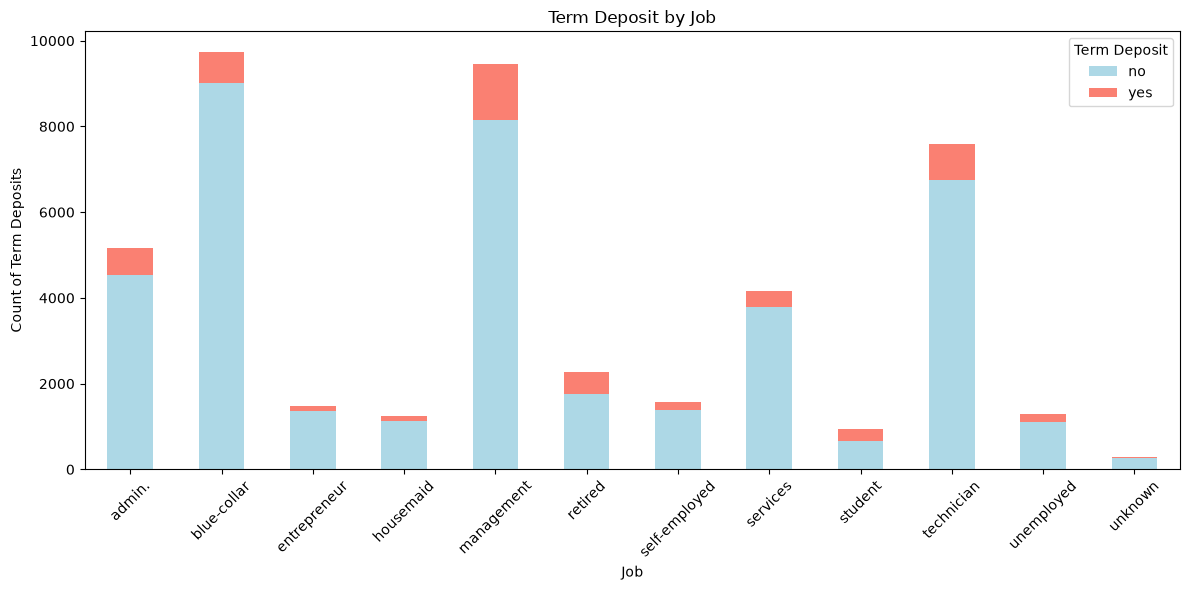

In [56]:
# create bar plot of term deposits by job
plt.figure(figsize=(12, 6))
# Group by job and count the number of term deposits
job_term_deposit_counts = data_full.groupby('job')['y'].value_counts().unstack().fillna(0)
job_term_deposit_counts.plot(kind='bar', stacked=True, color=['lightblue', 'salmon'], ax=plt.gca())
plt.title('Term Deposit by Job')
plt.xlabel('Job')
plt.ylabel('Count of Term Deposits')
plt.xticks(rotation=45)
plt.legend(title='Term Deposit', loc='upper right')
plt.tight_layout()
plt.show()

9. (4 คะแนน) Campaign Effectiveness
จงวิเคราะห์ความสัมพันธ์ระหว่างจำนวนครั้งที่ติดต่อลูกค้า (campaign) กับการสมัคร Term Deposit โดยใช้ Scatterplot หรือ Boxplot พร้อมอธิบายว่าการติดต่อลูกค้าหลายครั้งมีความสัมพันธ์กับโอกาสในการสมัครเพิ่มขึ้นหรือไม่

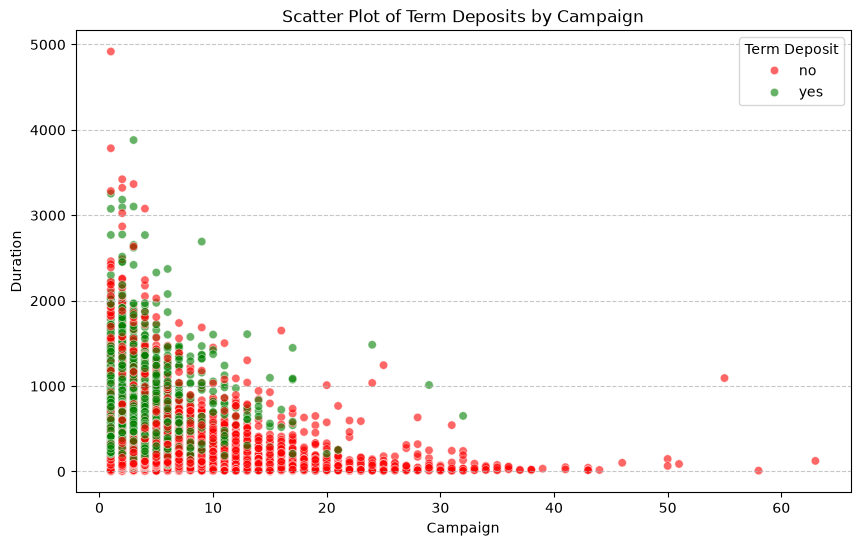

In [57]:
# create scatter plot of term deposits by campaign
plt.figure(figsize=(10, 6))
# Scatter plot of campaign vs. duration, colored by term deposit status
sns.scatterplot(data=data_full, x='campaign', y='duration', hue='y', palette={'yes': 'green', 'no': 'red'}, alpha=0.6)
plt.title('Scatter Plot of Term Deposits by Campaign')
plt.xlabel('Campaign')
plt.ylabel('Duration')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Term Deposit', loc='upper right')
plt.show()

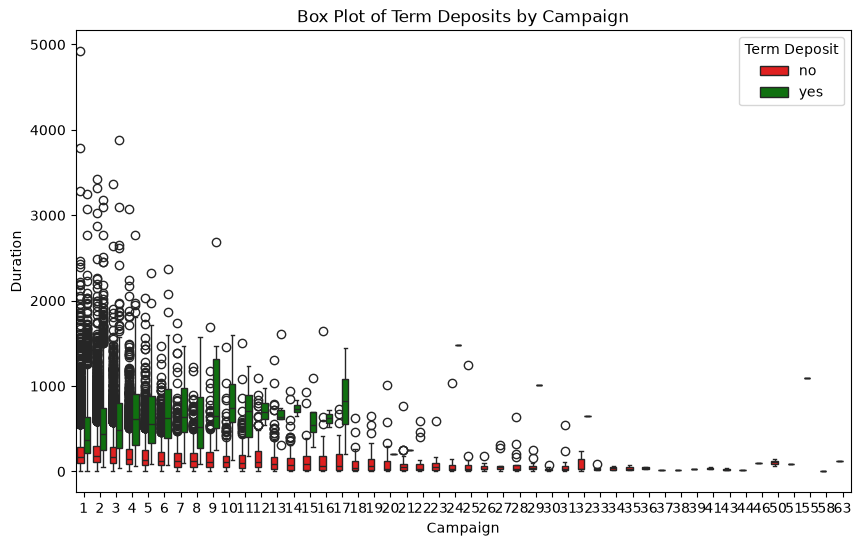

In [58]:
# create box plot of term deposits by campaign
plt.figure(figsize=(10, 6))
sns.boxplot(data=data_full, x='campaign', y='duration', hue='y', palette={'yes': 'green', 'no': 'red'})
plt.title('Box Plot of Term Deposits by Campaign')
plt.xlabel('Campaign')
plt.ylabel('Duration')
plt.legend(title='Term Deposit', loc='upper right')
plt.show()


10. (4 คะแนน) Previous Outcome Influence
จงวิเคราะห์ผลลัพธ์ของแคมเปญก่อนหน้า (poutcome) ที่มีความสัมพันธ์กับการสมัคร Term Deposit ในปัจจุบัน โดยใช้ Barplot เปรียบเทียบอัตราการสมัครของลูกค้าในแต่ละกลุ่ม ได้แก่ success, failure, other และ unknown พร้อมสรุปข้อค้นพบ (Insights) จากการวิเคราะห์

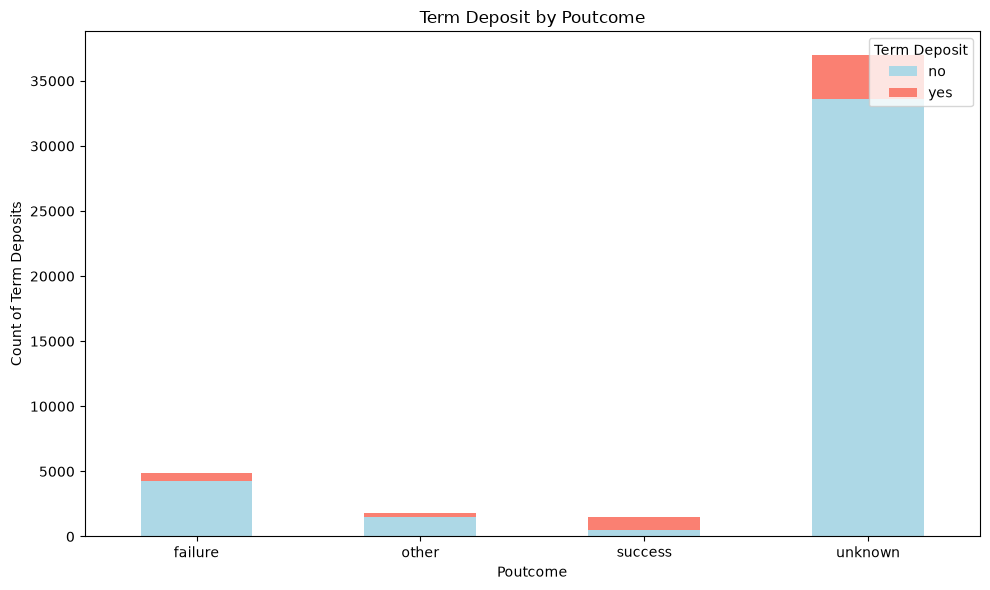

In [59]:
# create bar plot of Term Deposit by poutcome
plt.figure(figsize=(10, 6))
# Group by poutcome and count the number of term deposits
poutcome_term_deposit_counts = data_full.groupby('poutcome')['y'].value_counts().unstack().fillna(0)
poutcome_term_deposit_counts.plot(kind='bar', stacked=True, color=['lightblue', 'salmon'], ax=plt.gca())
plt.title('Term Deposit by Poutcome')
plt.xlabel('Poutcome')
plt.ylabel('Count of Term Deposits')
plt.xticks(rotation=0)
plt.legend(title='Term Deposit', loc='upper right')
plt.tight_layout()
plt.show()

# ส่วนที่ 2: Hypothesis-Based EDA

11. (4 คะแนน) Duration Effect
สมมติฐาน: ลูกค้าที่ใช้เวลาในการสนทนา (duration) นานกว่าจะมีแนวโน้มสมัคร Term Deposit มากกว่าลูกค้าที่ใช้เวลาในการสนทนาสั้นกว่า
การพิสูจน์สมมติฐาน: จงสร้าง Boxplot หรือ Histogram แสดงการกระจายของตัวแปร duration โดยแยกตามผลการสมัคร (y = yes/no) พร้อมวิเคราะห์และอธิบายว่าข้อมูลสนับสนุนสมมติฐานดังกล่าวหรือไม่

C:\Users\Maru\AppData\Local\Temp\ipykernel_5056\3987824089.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data_full, x='y', y='duration', palette={'yes': 'green', 'no': 'red'})


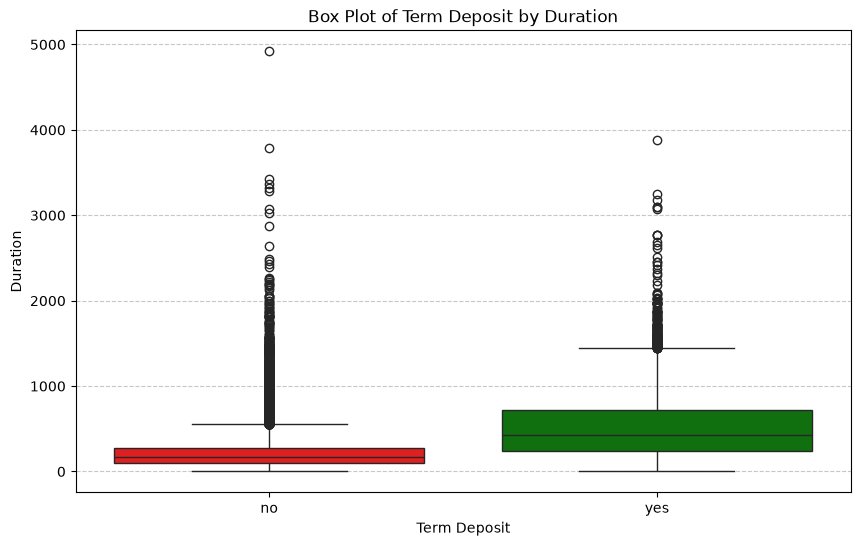

In [60]:
# create box plot of Term Deposit by duration
plt.figure(figsize=(10, 6))
sns.boxplot(data=data_full, x='y', y='duration', palette={'yes': 'green', 'no': 'red'})
plt.title('Box Plot of Term Deposit by Duration')
plt.xlabel('Term Deposit')
plt.ylabel('Duration')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

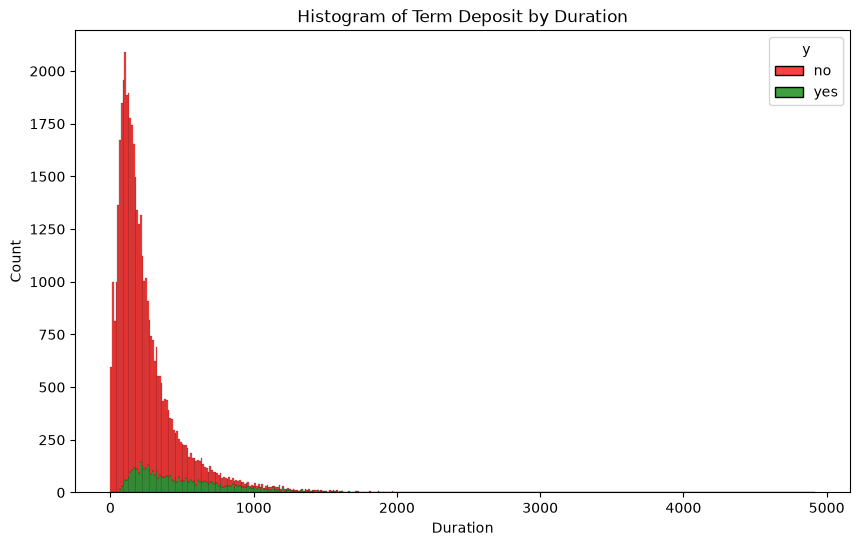

In [61]:
# create histogram of Term Deposit by duration
plt.figure(figsize=(10, 6))
sns.histplot(data=data_full, x='duration', hue='y', multiple='stack', palette={'yes': 'green', 'no': 'red'})
plt.title('Histogram of Term Deposit by Duration')
plt.xlabel('Duration')
plt.ylabel('Count')
plt.show()


12. (4 คะแนน) Education Impact
สมมติฐาน: ลูกค้าที่มีการศึกษาระดับอุดมศึกษา (tertiary) มีแนวโน้มสมัคร Term Deposit มากกว่าลูกค้าที่มีการศึกษาระดับอื่น
การพิสูจน์สมมติฐาน: จงสร้าง Barplot แสดงสัดส่วนการสมัคร (y = yes) ในแต่ละระดับการศึกษา (education) พร้อมเปรียบเทียบและอธิบายว่าผลการวิเคราะห์สอดคล้องกับสมมติฐานดังกล่าวหรือไม่

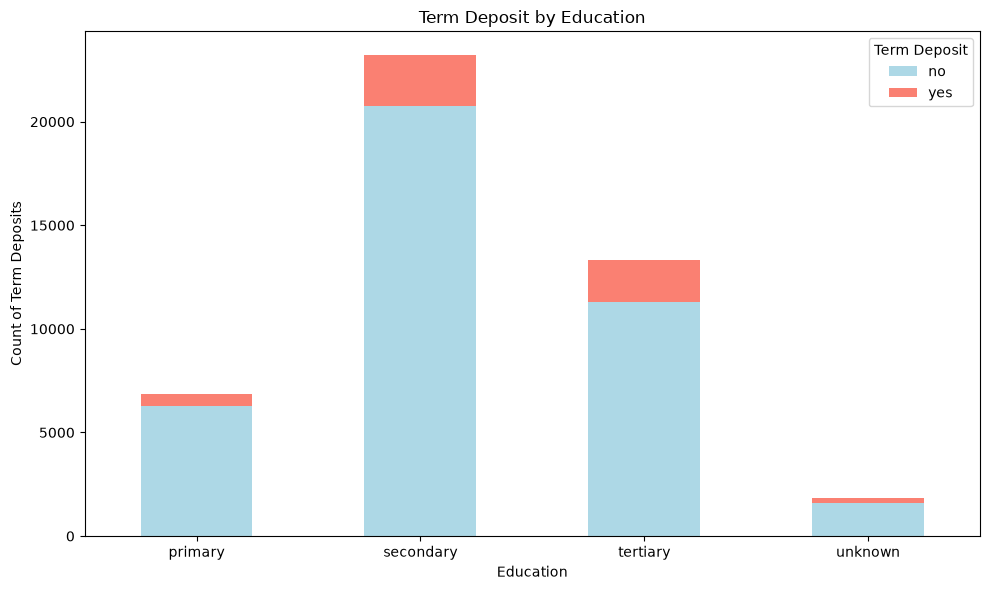

In [62]:
# create bar plot of Term Deposit by education
plt.figure(figsize=(10, 6))
# Group by education and count the number of term deposits
education_term_deposit_counts = data_full.groupby('education')['y'].value_counts().unstack().fillna(0)
education_term_deposit_counts.plot(kind='bar', stacked=True, color=['lightblue', 'salmon'], ax=plt.gca())
plt.title('Term Deposit by Education')
plt.xlabel('Education')
plt.ylabel('Count of Term Deposits')
plt.xticks(rotation=0)
plt.legend(title='Term Deposit', loc='upper right')
plt.tight_layout()
plt.show()

13. (4 คะแนน) Loan Constraint
สมมติฐาน: ลูกค้าที่มีสินเชื่อส่วนบุคคล (loan = yes) มีแนวโน้มสมัคร Term Deposit น้อยกว่าลูกค้าที่ไม่มีสินเชื่อส่วนบุคคล (loan = no)
การพิสูจน์สมมติฐาน: จงสร้าง Stacked Barplot หรือตารางไขว้ (Crosstab Table) เพื่อเปรียบเทียบสัดส่วนการสมัคร (y = yes/no) ระหว่างกลุ่มลูกค้าที่มีและไม่มีสินเชื่อส่วนบุคคล พร้อมวิเคราะห์และอธิบายว่าข้อมูลสนับสนุนสมมติฐานดังกล่าวหรือไม่

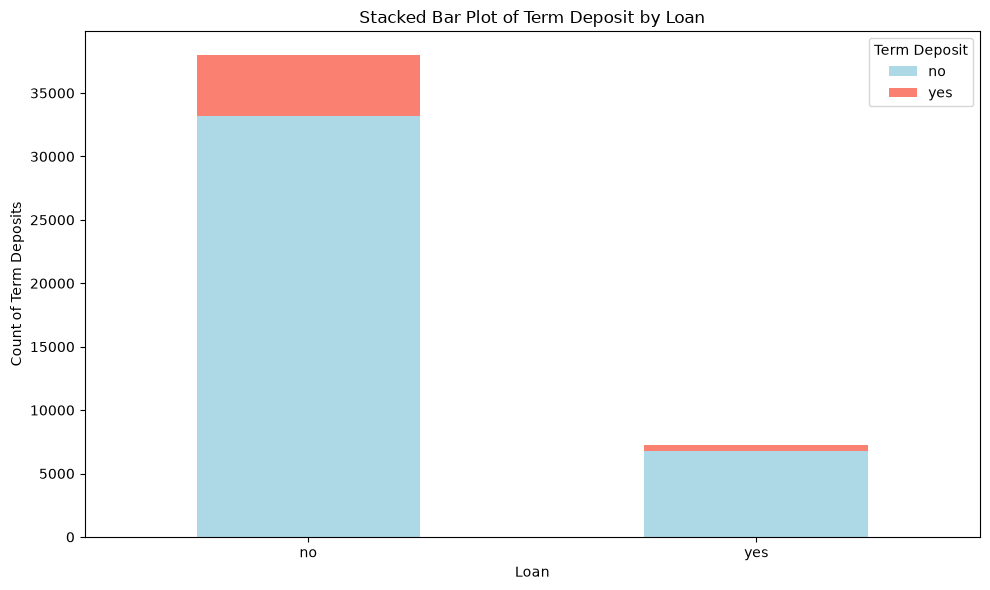

In [63]:
# create stacked bar plot of Term Deposit by loan
plt.figure(figsize=(10, 6))
# Create a crosstab of loan against term deposit
loan_term_deposit_crosstab = pd.crosstab(data_full['loan'], data_full['y'])
loan_term_deposit_crosstab.plot(kind='bar', stacked=True, color=['lightblue', 'salmon'], ax=plt.gca())
plt.title('Stacked Bar Plot of Term Deposit by Loan')
plt.xlabel('Loan')
plt.ylabel('Count of Term Deposits')
plt.xticks(rotation=0)
plt.legend(title='Term Deposit', loc='upper right')
plt.tight_layout()
plt.show()

14. (4 คะแนน) Contact Method Effect
สมมติฐาน: ลูกค้าที่ได้รับการติดต่อผ่านโทรศัพท์มือถือ (contact = cellular) มีแนวโน้มสมัคร Term Deposit มากกว่าลูกค้าที่ได้รับการติดต่อผ่านโทรศัพท์พื้นฐาน (contact = telephone)
การพิสูจน์สมมติฐาน: จงสร้าง Barplot เปรียบเทียบสัดส่วนการสมัคร (y = yes) ระหว่างกลุ่มลูกค้าที่ได้รับการติดต่อผ่าน cellular และ telephone พร้อมวิเคราะห์และอธิบายว่าผลการวิเคราะห์สอดคล้องกับสมมติฐานดังกล่าวหรือไม่

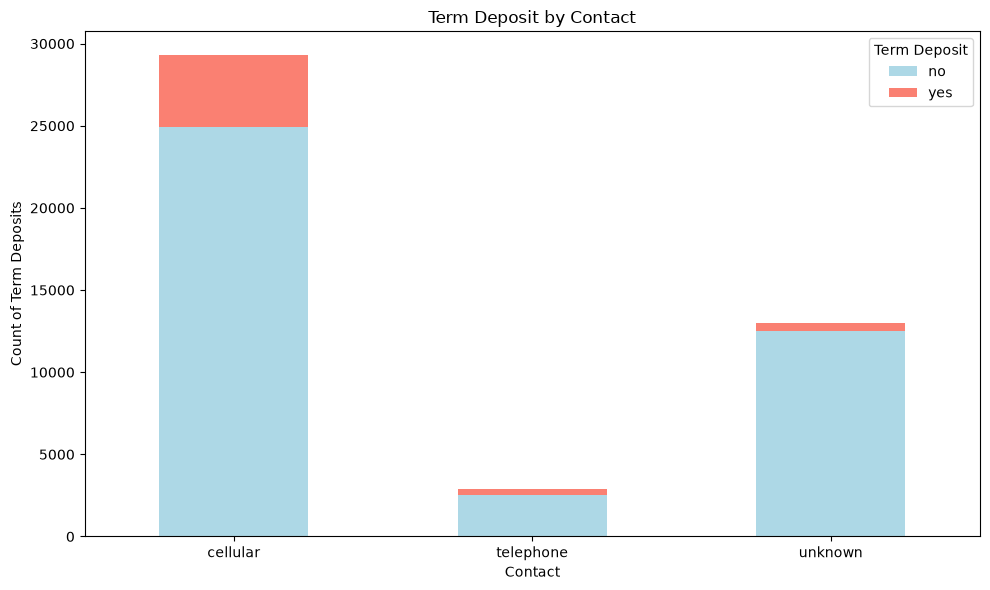

In [64]:
# create bar plot of Term Deposit by contact (cellular, telephone)
plt.figure(figsize=(10, 6))
# Group by contact and count the number of term deposits
contact_term_deposit_counts = data_full.groupby('contact')['y'].value_counts().unstack().fillna(0)
contact_term_deposit_counts.plot(kind='bar', stacked=True, color=['lightblue', 'salmon'], ax=plt.gca())
plt.title('Term Deposit by Contact')
plt.xlabel('Contact')
plt.ylabel('Count of Term Deposits')
plt.xticks(rotation=0)
plt.legend(title='Term Deposit', loc='upper right')
plt.tight_layout()
plt.show()

15. (4 คะแนน) Campaign Timing Effect
สมมติฐาน: ลูกค้าที่ได้รับการติดต่อจำนวนน้อยครั้ง (campaign มีค่าต่ำ) มีแนวโน้มสมัคร Term Deposit มากกว่าลูกค้าที่ได้รับการติดต่อหลายครั้ง (campaign มีค่าสูง)
การพิสูจน์สมมติฐาน: จงสร้าง Boxplot หรือ Scatterplot แสดงความสัมพันธ์ระหว่างจำนวนครั้งที่ติดต่อลูกค้า (campaign) กับผลการสมัคร (y) พร้อมวิเคราะห์และอธิบายว่าข้อมูลสนับสนุนสมมติฐานดังกล่าวหรือไม่

C:\Users\Maru\AppData\Local\Temp\ipykernel_5056\4117364446.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data_full, x='y', y='campaign', palette={'yes': 'green', 'no': 'red'})


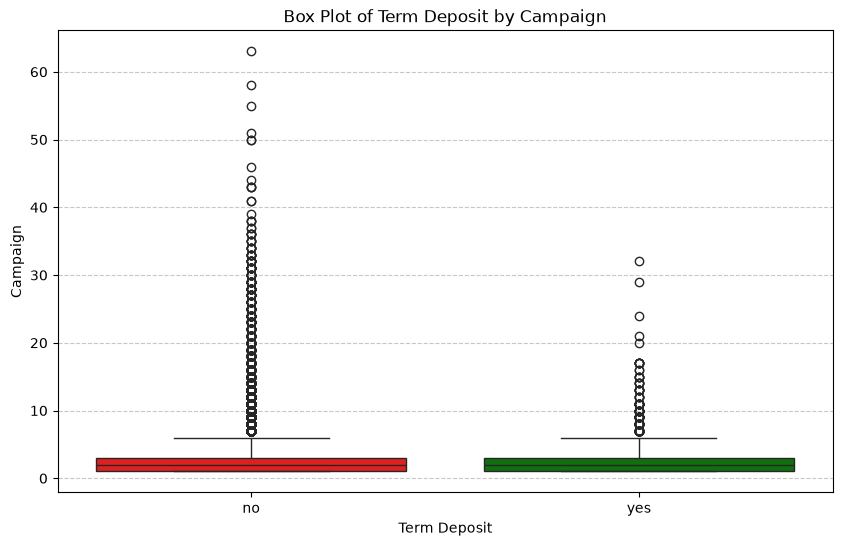

In [65]:
# create box plot of Term Deposit by campaign
plt.figure(figsize=(10, 6))
sns.boxplot(data=data_full, x='y', y='campaign', palette={'yes': 'green', 'no': 'red'})
plt.title('Box Plot of Term Deposit by Campaign')
plt.xlabel('Term Deposit')
plt.ylabel('Campaign')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

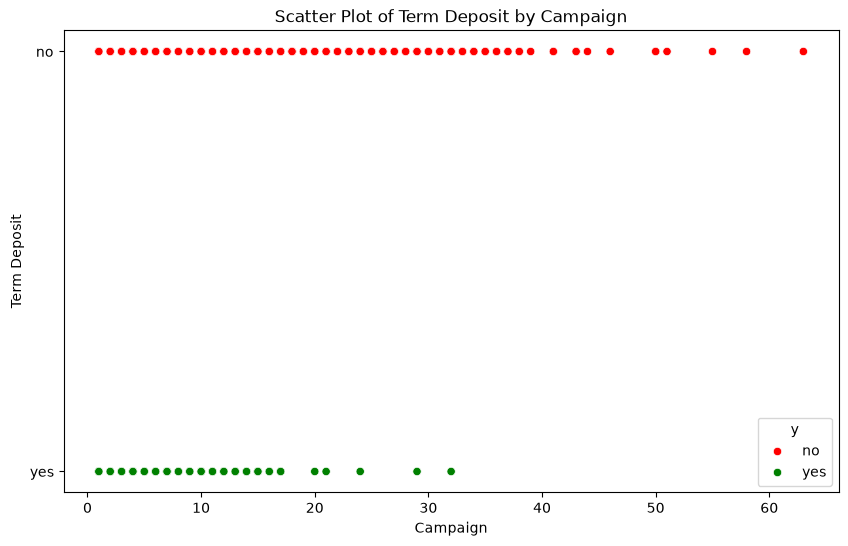

In [66]:
# create scatter plot of Term Deposit by campaign
plt.figure(figsize=(10, 6))
sns.scatterplot(data=data_full, x='campaign', y='y', hue='y', palette={'yes': 'green', 'no': 'red'})
plt.title('Scatter Plot of Term Deposit by Campaign')
plt.xlabel('Campaign')
plt.ylabel('Term Deposit')
plt.show()
